<div align="center">

<h1>Neural Network from Scratch</h1>

<p>
Exploring the <b>mathematics</b> behind neural networks through a <b>pure NumPy</b> implementation (No TensorFlow or PyTorch)

<p>
<img src="https://img.shields.io/badge/Python-NumPy-blue?style=flat-square">
<img src="https://img.shields.io/badge/Dataset-MNIST-green?style=flat-square">
<img src="https://img.shields.io/badge/Implementation-From%20Scratch-orange?style=flat-square">
</p>

</div>


<div align="center">
    <img src="theoretical-notes/neural_network_math.jpg" width="750">
</div>

<div align="center">

<p><b>Data Preprocessing</b></p>
</div>

In [6]:
from torchvision import datasets

# MNIST dataset
# 28x28 images of handwritten digits (0-9)
# download training data (60k images)
train_data = datasets.MNIST(
    root='./data',
    train=True,
    download=True,
)

# download test data (10k images)
test_data = datasets.MNIST(
    root='./data',
    train=False,
    download=True,
)





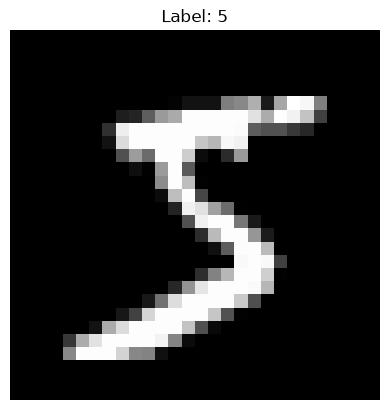

In [7]:
import numpy as np
import matplotlib.pyplot as plt

x_train = train_data.data.numpy().reshape(-1, 784)
x_train = x_train.astype(np.float32) / 255.0

y_train = np.eye(10, dtype=np.float32)[train_data.targets.numpy()]


x_test = test_data.data.numpy().reshape(-1, 784)
x_test = x_test.astype(np.float32) / 255.0

y_test = np.eye(10, dtype=np.float32)[test_data.targets.numpy()]

image, label = train_data[0]

plt.imshow(image, cmap='gray')
plt.title(f'Label: {label}')
plt.axis('off')
plt.show()



<div align="center">

<p><b>Implementation</b></p>

</div>

In [8]:
# activation function --> ReLu(x) = max(0,x) 
def relu(x):
    return np.maximum(0, x)

# activation function --> converts raw scores(logits) into a probability distribution
def softmax(x):
    exp_x = np.exp(x - np.max(x,axis=-1, keepdims=True)) 
    return exp_x / np.sum(exp_x, axis=-1, keepdims=True)

### LOSS CALCULATION
# categorical cross-entropy (CCE)        with numpy
def cce(y_true, y_pred):
    N = y_true.shape[0]
    
    y_pred = np.clip(y_pred, 1e-15, 1.0)
    
    return -np.sum(y_true * np.log(y_pred)) / N 

In [9]:
class NeuralNetwork: 
    def __init__(self, layers):
        self.layers = layers
        self.initialize_parameters()
    
    # He initialization
    def initialize_parameters(self):
        self.weights = []
        self.biases = []
        
        for i in range(len(self.layers)-1):
            W = np.random.randn(self.layers[i+1], self.layers[i]) * np.sqrt(2 / self.layers[i])
            b = np.zeros(self.layers[i+1])
            
            self.weights.append(W)
            self.biases.append(b)
    
    
    def forward_propagation(self, x):
        activations = [x]
        pre_activations = []
        
        # hidden layer
        for i, (W,b) in enumerate(zip(self.weights, self.biases)):
            z = activations[-1] @ W.T + b
            pre_activations.append(z)
            
            if i == len(self.weights) -1:
                a = softmax(z)
            else:
                a = relu(z)
            
            activations.append(a)
        
        return activations, pre_activations
    
    
    def backward_propagation(self, y_true, activations, pre_activations):
        dW = [None] * len(self.weights)
        db = [None] * len(self.weights)
        
        N = y_true.shape[0]
        
        # Softmax + CCE derivative
        dZ = (activations[-1] - y_true) / N
        
        for i in reversed(range(len(self.weights))):
            A_prev = activations[i]
            
            # gradients of weights and biases
            dW[i] = dZ.T @ A_prev
            db[i] = np.sum(dZ, axis=0)
            
            # propagate error to previous layer
            if i > 0:
                dA_prev = dZ @ self.weights[i]
                dZ = dA_prev * (pre_activations[i-1] > 0)
            
        return dW, db
    
    def gradient_descent(self, dW, db, alpha):
        for i in range(len(self.weights)):
            self.weights[i] = self.weights[i] - alpha * dW[i]
            self.biases[i] = self.biases[i] - alpha * db[i]
            
            
    def train(self, X, Y, epochs, alpha):
        for epoch in range(epochs):
            activations, pre_activations = self.forward_propagation(X)
            loss = cce(Y, activations[-1])
            
            dW, db = self.backward_propagation(Y, activations, pre_activations)
            
            self.gradient_descent(dW, db, alpha)
            
            if epoch % 10 == 0:
                print(f"Epoch {epoch}: loss = {loss:.4f}")
                
    def test(self, X, Y):
        activations, _ = self.forward_propagation(X)
        
        y_pred = np.argmax(activations[-1], axis=1)
        y_true = np.argmax(Y, axis=1)
        
        accuracy = np.mean(y_pred == y_true)
        
        return accuracy
    
    def save(self, filename):
        np.savez(filename,
                 layers=self.layers,
                 **{f"W{i}": W for i, W in enumerate(self.weights)},
                 **{f"b{i}": b for i, b in enumerate(self.biases)}
                )
    
    @classmethod
    def load(cls, filename):
        data = np.load(filename)
        
        nn = cls(data["layers"].tolist())
        
        for i in range(len(nn.weights)):
            nn.weights[i] = data[f"W{i}"]
            nn.biases[i] = data[f"b{i}"]
        
        return nn
        
            
            
    
    
    

<div align="center">

<p><b>Example</b></p>

</div>

In [10]:
nn = NeuralNetwork([784,128,64,10])
nn.train(x_train, y_train, 200, 0.05)

print(nn.test(x_test,y_test))

nn.save("mnist_neural_network_example.npz")

Epoch 0: loss = 2.3360
Epoch 10: loss = 1.9565
Epoch 20: loss = 1.6052
Epoch 30: loss = 1.2838
Epoch 40: loss = 1.0352
Epoch 50: loss = 0.8639
Epoch 60: loss = 0.7483
Epoch 70: loss = 0.6678
Epoch 80: loss = 0.6093
Epoch 90: loss = 0.5650
Epoch 100: loss = 0.5305
Epoch 110: loss = 0.5027
Epoch 120: loss = 0.4798
Epoch 130: loss = 0.4607
Epoch 140: loss = 0.4443
Epoch 150: loss = 0.4302
Epoch 160: loss = 0.4178
Epoch 170: loss = 0.4068
Epoch 180: loss = 0.3970
Epoch 190: loss = 0.3882
0.902


## TODO

- [x] RELU
- [x] Softmax
- [x] Initialize Parameters
- [x] Forward Propagation
- [x] Backward Propagation
- [x] Gradient Descent